# Exercise 2: Image Compression Using K-Means Clustering

**Subject:** Machine Learning Lab  
**Topic:** K-Means Clustering

## Aim
To perform image compression using K-Means clustering by grouping similar pixel colors and representing them using a smaller set of colors.

Original image shape: (100, 100, 3)
Total pixels: 10000
Number of colors before compression: many
Number of colors after compression: 4


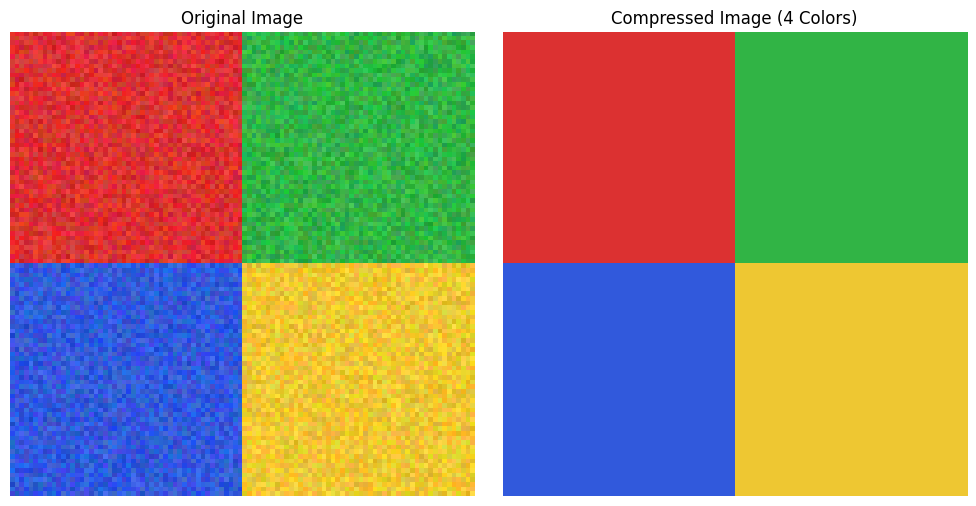

Representative colors (RGB):
[[221  50  50]
 [ 50  90 220]
 [ 50 180  70]
 [239 200  51]]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Create a sample colorful image
np.random.seed(42)
image = np.zeros((100, 100, 3), dtype=np.uint8)
image[:50, :50] = [220, 50, 50]      # Red
image[:50, 50:] = [50, 180, 70]      # Green
image[50:, :50] = [50, 90, 220]      # Blue
image[50:, 50:] = [240, 200, 50]     # Yellow

# Add slight color variations
noise = np.random.randint(-25, 26, image.shape)
image = np.clip(image.astype(int) + noise, 0, 255).astype(np.uint8)

# Reshape pixels into a 2D array
pixels = image.reshape(-1, 3)
print("Original image shape:", image.shape)
print("Total pixels:", len(pixels))

# Apply K-Means to reduce colors
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(pixels)

compressed_pixels = kmeans.cluster_centers_[labels]
compressed_image = np.clip(compressed_pixels.reshape(image.shape), 0, 255).astype(np.uint8)

print("Number of colors before compression: many")
print("Number of colors after compression:", k)

# Display original and compressed images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(compressed_image)
plt.title(f"Compressed Image ({k} Colors)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display the learned representative colors
print("Representative colors (RGB):")
print(np.round(kmeans.cluster_centers_).astype(int))

## Result

The K-Means clustering algorithm was successfully implemented for image color compression using Python.

- **Original image size:** 100 × 100 pixels
- **Total pixels:** 10,000
- **Number of clusters (K):** 4
- **Original image:** Contains color variations due to added noise
- **Compressed image:** Uses four representative colors

The original and compressed images were displayed side by side to demonstrate the reduction in color variation.

## Conclusion

The experiment demonstrated how K-Means clustering can be used for image color quantization. By grouping similar pixel colors and replacing them with cluster-centroid colors, the image was simplified while retaining its main color regions. This experiment illustrates color reduction rather than a complete file-size compression benchmark.